In [27]:
# إعداد المسارات

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path(
    "/content/drive/MyDrive/DEPI_Graduation_Project"
)

DATA_DIR = PROJECT_DIR / "data" / "cleaned"

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

FIGURES_DIR = PROJECT_DIR / "reports" / "figures"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (12, 6)

print("Project:", PROJECT_DIR)
print("Cleaned Data:", DATA_DIR)
print("Processed Data:", PROCESSED_DIR)
print("Figures:", FIGURES_DIR)

Project: /content/drive/MyDrive/DEPI_Graduation_Project
Cleaned Data: /content/drive/MyDrive/DEPI_Graduation_Project/data/cleaned
Processed Data: /content/drive/MyDrive/DEPI_Graduation_Project/data/processed
Figures: /content/drive/MyDrive/DEPI_Graduation_Project/reports/figures


1. إيه طبيعة توزيع المبيعات؟
2. هل فيه Trends وSeasonality في المبيعات؟
3. إيه تأثير الأيام والعروض الترويجية؟
4. هل اختلاف أنواع المتاجر والمنافسة والعطلات مرتبط باختلاف المبيعات؟
## 5. إيه أهم المعلومات اللي نقدر نحولها إلى Features للموديل؟ 

In [29]:
# التأكد من وجود الملفات

required_files = [
    "train_cleaned.parquet",
    "test_cleaned.parquet",
    "store_cleaned.parquet"
]

for filename in required_files:
    file_path = DATA_DIR / filename

    print(
        filename,
        "->",
        "Found" if file_path.exists() else "Missing"
    )

  #  تحميل الداتا

train = pd.read_parquet(DATA_DIR / "train_cleaned.parquet")
test = pd.read_parquet(DATA_DIR / "test_cleaned.parquet")
store = pd.read_parquet(DATA_DIR / "store_cleaned.parquet")

print("Train:", train.shape)
print("Test:", test.shape)
print("Store:", store.shape)

train_cleaned.parquet -> Found
test_cleaned.parquet -> Found
store_cleaned.parquet -> Found
Train: (1017209, 9)
Test: (41088, 8)
Store: (1115, 12)


In [30]:
# دمج بيانات المتاجر
# كل Store ليه بيانات ثابتة في store، لكن عندنا سجلات يومية كتير لنفس المتجر في train وtest.

train_merged = train.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

test_merged = test.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

assert len(train_merged) == len(train)
assert len(test_merged) == len(test)

print("Train merged:", train_merged.shape)
print("Test merged:", test_merged.shape)

Train merged: (1017209, 20)
Test merged: (41088, 19)


In [57]:
# EDA — General Overview

display(train.head())

print("\nDataset Information:")
train.info()

print("\nStatistical Summary:")
display(train.describe().T)

print("\nMissing Values:")
display(
    train.isnull().sum()
    .to_frame("Missing Values")
    .query("`Missing Values` > 0")
)

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype         
---  ------         --------------    -----         
 0   Store          1017209 non-null  int16         
 1   DayOfWeek      1017209 non-null  int8          
 2   Date           1017209 non-null  datetime64[ns]
 3   Sales          1017209 non-null  int32         
 4   Customers      1017209 non-null  int32         
 5   Open           1017209 non-null  int8          
 6   Promo          1017209 non-null  int8          
 7   StateHoliday   1017209 non-null  category      
 8   SchoolHoliday  1017209 non-null  int8          
dtypes: category(1), datetime64[ns](1), int16(1), int32(2), int8(4)
memory usage: 22.3 MB

Statistical Summary:


,count,mean,min,25%,50%,75%,max,std
Store,1017209.0,558.429727,1.0,280.0,558.0,838.0,1115.0,321.908651
DayOfWeek,1017209.0,3.998341,1.0,2.0,4.0,6.0,7.0,1.997391
Date,1017209,2014-04-11 01:30:42.846061824,2013-01-01 00:00:00,2013-08-17 00:00:00,2014-04-02 00:00:00,2014-12-12 00:00:00,2015-07-31 00:00:00,NaN
Sales,1017209.0,5773.818972,0.0,3727.0,5744.0,7856.0,41551.0,3849.926175
Customers,1017209.0,633.145946,0.0,405.0,609.0,837.0,7388.0,464.411734
Open,1017209.0,0.830107,0.0,1.0,1.0,1.0,1.0,0.375539
Promo,1017209.0,0.381515,0.0,0.0,0.0,1.0,1.0,0.485759
SchoolHoliday,1017209.0,0.178647,0.0,0.0,0.0,0.0,1.0,0.383056



Missing Values:


,Missing Values


# **Sales Distribution**

***Target Distribution***

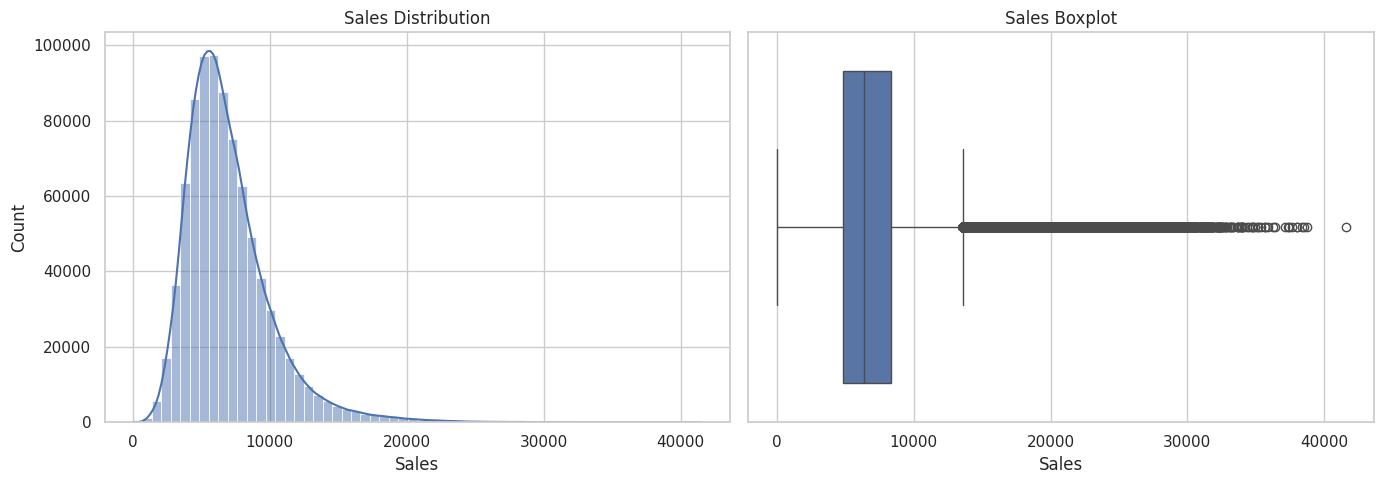

In [58]:
# هنحلل المبيعات في الأيام اللي المتاجر كانت مفتوحة فيها.
open_sales = train[train["Open"] == 1].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=open_sales,
    x="Sales",
    bins=60,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Sales Distribution")

sns.boxplot(
    data=open_sales,
    x="Sales",
    ax=axes[1]
)

axes[1].set_title("Sales Boxplot")

plt.tight_layout()
plt.savefig(
    FIGURES_DIR / "sales_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

*Right-Skewed*

Sales aren't distributed normally, and there are stores and days that achieve sales much higher than the average.

We won't delete the outliers because we reviewed them during the cleaning stage and found that a large part of them are actual sales

# ***Sales Over Time***

***Daily Sales Trend***

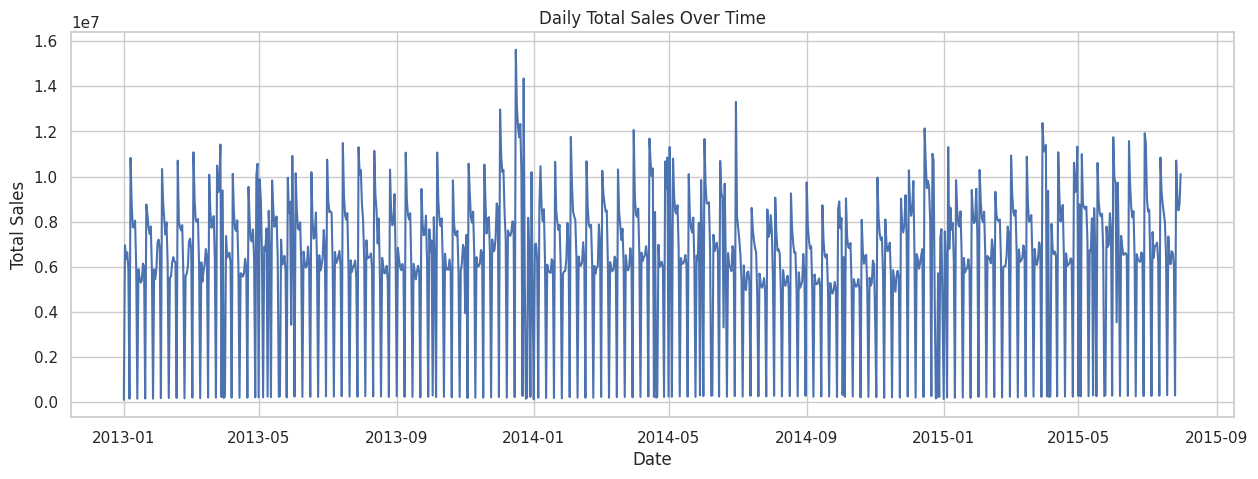

In [59]:
daily_sales = (
    open_sales.groupby("Date")
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(15, 5))

sns.lineplot(
    data=daily_sales,
    x="Date",
    y="Total_Sales"
)

plt.title("Daily Total Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.savefig(
    FIGURES_DIR / "daily_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# **Time Patterns**

***Sales by Day of Week***

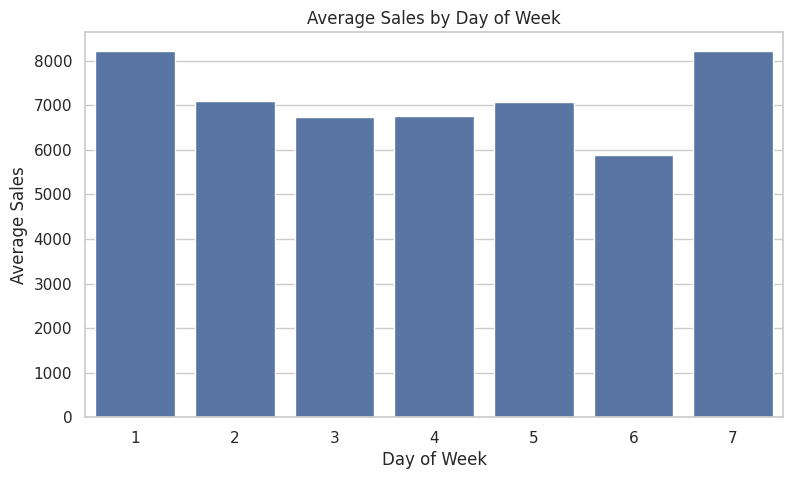

In [60]:
weekday_sales = (
    open_sales.groupby("DayOfWeek")["Sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=weekday_sales,
    x="DayOfWeek",
    y="Sales"
)

plt.title("Average Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Sales")

plt.savefig(
    FIGURES_DIR / "sales_by_weekday.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

*Monday (the first day of the week) and Sunday (the weekend holiday) are the top performing days.*

Is the difference in average sales between weekdays real, or is it because the number of stores open is different?

In [69]:
weekday_analysis = (
    open_sales.groupby("DayOfWeek")
    .agg(
        Average_Sales=("Sales", "mean"),
        Total_Sales=("Sales", "sum"),
        Open_Stores=("Store", "nunique"),
        Records=("Sales", "count")
    )
    .reset_index()
)

display(weekday_analysis)

,DayOfWeek,Average_Sales,Total_Sales,Open_Stores,Records
0,1,8216.073074,1130203012,1115,137560
1,2,7088.113656,1020411930,1115,143961
2,3,6728.122978,954962863,1115,141936
3,4,6767.310159,911177709,1115,134644
4,5,7072.677012,980555941,1115,138640
5,6,5874.840238,846317735,1115,144058
6,7,8224.723908,29551433,33,3593


*On Sunday, there are only 33 stores open, compared to 1,115 stores on the other days. *

*So the high average sales on Sunday doesn't necessarily mean that Sunday is the best day for sales; *

---
Monday has almost the highest average sales among the days most stores are open.

Saturday has the lowest average sales.

Sunday isn't really comparable to the other days because the number of stores open is different.


***Monthly Sales***

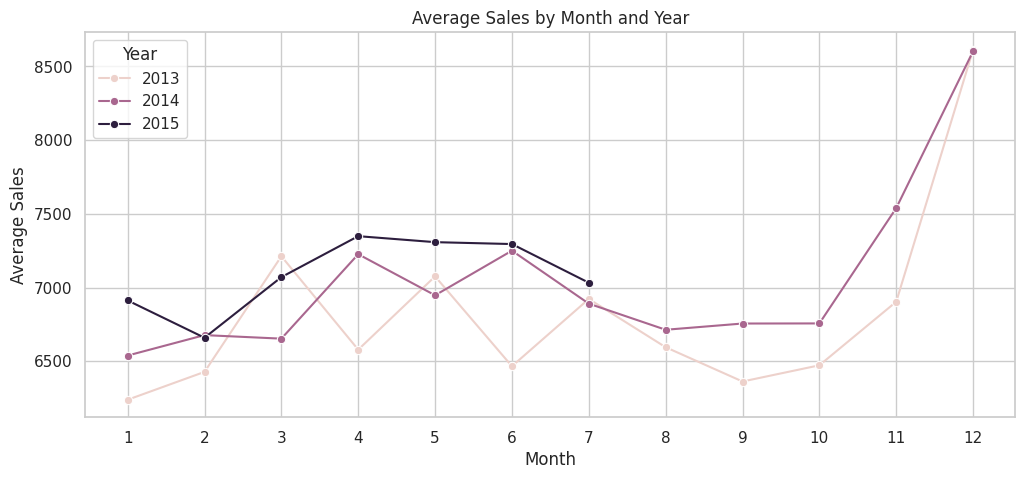

In [61]:
monthly_sales = (
    open_sales.assign(
        Year=open_sales["Date"].dt.year,
        Month=open_sales["Date"].dt.month
    )
    .groupby(["Year", "Month"])["Sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Sales",
    hue="Year",
    marker="o"
)

plt.title("Average Sales by Month and Year")
plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.xticks(range(1, 13))

plt.savefig(
    FIGURES_DIR / "monthly_sales.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# **Promotion Analysis**

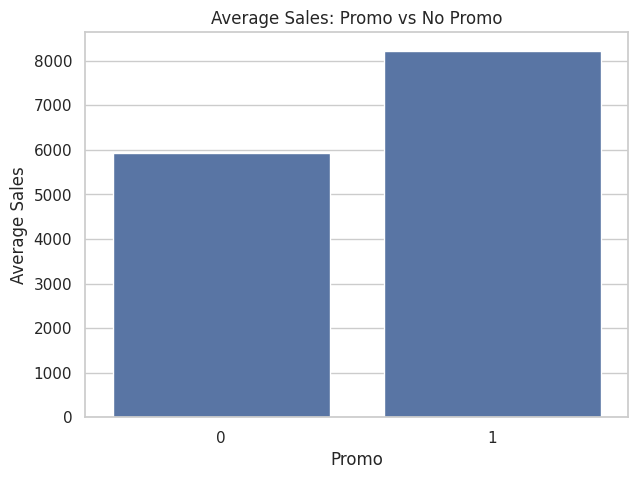

,Promo,Sales
0,0,5929.407603
1,1,8228.281239


In [62]:
promo_sales = (
    open_sales.groupby("Promo")["Sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(7, 5))

sns.barplot(
    data=promo_sales,
    x="Promo",
    y="Sales"
)

plt.title("Average Sales: Promo vs No Promo")
plt.xlabel("Promo")
plt.ylabel("Average Sales")

plt.savefig(
    FIGURES_DIR / "promo_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(promo_sales)

*Stores that have promotional offers record average sales about 39% higher.*

# **Store Analysis**

***Sales by Store Type***

In [67]:
print(open_sales.columns.tolist())

print(train.columns.tolist())
print(store.columns.tolist())

train_merged = train.merge(
    store,
    on="Store",
    how="left",
    validate="many_to_one"
)

open_sales = train_merged[
    train_merged["Open"] == 1
].copy()

['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']
['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday']
['Store', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'CompetitionDistance_WasMissing', 'CompetitionDateKnown']


### Creating the Open Sales Dataset

Initially, the `open_sales` DataFrame was created from the original training dataset before merging it with the store information.

As a result, it did not contain the `StoreType` column, which caused a `KeyError` when grouping sales by store type.

**Solution:**
- Merged the training data with the store metadata using the `Store` column.
- Created a new `open_sales` DataFrame from the merged dataset.
- Filtered records where `Open = 1` to analyze sales only on days when stores were operating.

This ensures that `open_sales` contains both daily sales information and store characteristics, allowing further analysis by `StoreType`, `Assortment`, and other store-related features.

/tmp/ipykernel_869/284695310.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  open_sales.groupby("StoreType")["Sales"]


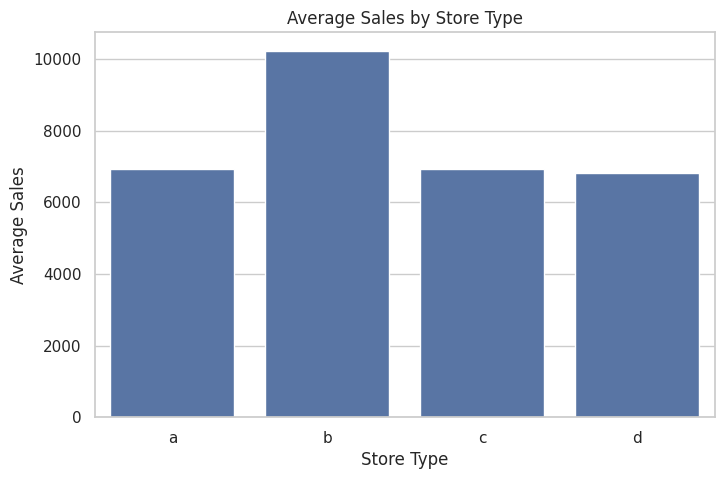

,StoreType,Sales
0,a,6925.167661
1,b,10231.407505
2,c,6932.512755
3,d,6822.141881


In [68]:
store_sales = (
    open_sales.groupby("StoreType")["Sales"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=store_sales,
    x="StoreType",
    y="Sales"
)

plt.title("Average Sales by Store Type")
plt.xlabel("Store Type")
plt.ylabel("Average Sales")

plt.savefig(
    FIGURES_DIR / "store_type_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(store_sales)

**What can we consider important features?**
DayOfWeek, Month, Promo, StoreType and Year